## Data setup (Colab)

The STEP 2 cell loads `train.csv` from the first place it finds:

1. local folder / `/content/` / `/kaggle/input/digit-recognizer/`
2. Kaggle via `kagglehub` (needs an API token)
3. **automatic fallback: OpenML MNIST** — no login needed. It writes `train.csv`
   (60,000 x 785) and `test.csv` (10,000 x 784) in the same Kaggle format.

So on Colab you can simply `Runtime > Run all`. To use the official Kaggle files instead,
add your token first:
```python
!pip install -q kagglehub
import kagglehub
kagglehub.competition_download('digit-recognizer')
```

In [14]:
# %% STEP 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [15]:
# %% STEP 2: load train CSV (Colab + local, no Kaggle login required)
import os
import glob
import pandas as pd

CANDIDATES = [
    'train.csv', 'lab08/train.csv', '/content/train.csv',
    '/kaggle/input/digit-recognizer/train.csv',
] + glob.glob('/kaggle/input/*/train.csv') + glob.glob('/content/*/train.csv')

TRAIN_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)

# If the Kaggle files are absent, try kagglehub (needs API token), then fall back
# to OpenML MNIST - identical format: 784 pixel columns + a 'label' column.
if TRAIN_PATH is None:
    try:
        import kagglehub
        TRAIN_PATH = os.path.join(kagglehub.competition_download('digit-recognizer'), 'train.csv')
        print('Loaded digit-recognizer via kagglehub')
    except Exception as e:
        print('Kaggle unavailable (%s) -> using OpenML MNIST instead.' % type(e).__name__)
        from sklearn.datasets import fetch_openml
        mn = fetch_openml('mnist_784', version=1, as_frame=True)
        X_all = mn.data.astype('uint8')
        y_all = mn.target.astype(int)
        tr = X_all.iloc[:60000].copy()
        tr.insert(0, 'label', y_all.iloc[:60000].values)
        tr.to_csv('train.csv', index=False)
        X_all.iloc[60000:].reset_index(drop=True).to_csv('test.csv', index=False)
        TRAIN_PATH = 'train.csv'
        print('Created train.csv (60,000 rows) and test.csv (10,000 rows).')

print('Using:', TRAIN_PATH)
df = pd.read_csv(TRAIN_PATH)
print('Data shape:', df.shape)
df.head()


Using: train.csv
Data shape: (60000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [16]:
# %% STEP 3: Data Preprocessing
# Label save as y and pixels save as X
y = df.iloc[:, 0].values
X = df.iloc[:, 1:].values

# Normalization: pixel values 0-255 to 0-1 range
X = X.astype("float32") / 255.0

# Reshape: 784 -> 28 x 28 x 1 (height, width, channel)
X = X.reshape(-1, 28, 28, 1)

print("X shape:", X.shape, " y shape:", y.shape)

X shape: (60000, 28, 28, 1)  y shape: (60000,)


In [17]:
# %% STEP 4: Training and Validation split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Validation:", X_val.shape)

Train: (48000, 28, 28, 1)  Validation: (12000, 28, 28, 1)


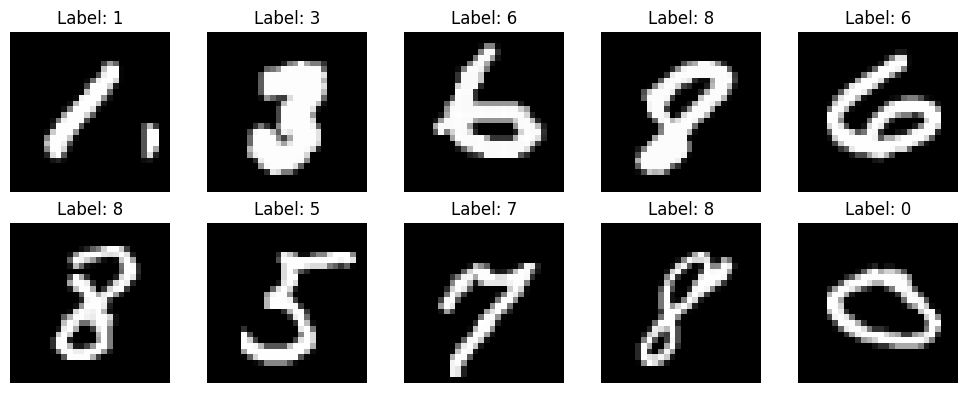

In [18]:
# %% STEP 5: Show some images (data check)
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title("Label: " + str(y_train[i]))
    plt.axis("off")
plt.tight_layout()
plt.show()

In [19]:
# %% STEP 6: CNN model
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # --- Block 1 ---
    layers.Conv2D(32, (3, 3)),          # Convolution (32 filters, 3x3)
    layers.Activation("relu"),          # ReLU
    layers.MaxPooling2D((2, 2)),        # Max Pooling 2x2

    # --- Block 2 ---
    layers.Conv2D(64, (3, 3)),          # Convolution (64 filters)
    layers.Activation("relu"),          # ReLU
    layers.MaxPooling2D((2, 2)),        # Max Pooling

    # --- Classifier ---
    layers.Flatten(),                   # 2D feature maps -> 1D vector
    layers.Dense(128),                  # Fully Connected layer
    layers.Activation("relu"),
    layers.Dropout(0.3),                # overfitting kam karne ke liye
    layers.Dense(10),                   # 10 classes (digits 0-9)
    layers.Activation("softmax"),       # Softmax -> probabilities
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# %% STEP 7: Model compile
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",   # labels integer (0-9)
    metrics=["accuracy"],
)

In [21]:
# %% STEP 8: Training
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val, y_val),
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9340 - loss: 0.2165 - val_accuracy: 0.9805 - val_loss: 0.0681
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9787 - loss: 0.0696 - val_accuracy: 0.9849 - val_loss: 0.0488
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9842 - loss: 0.0510 - val_accuracy: 0.9868 - val_loss: 0.0445
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9882 - loss: 0.0394 - val_accuracy: 0.9883 - val_loss: 0.0393
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9895 - loss: 0.0339 - val_accuracy: 0.9889 - val_loss: 0.0349
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9914 - loss: 0.0279 - val_accuracy: 0.9871 - val_loss: 0.0447
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9931 - loss: 0.0224 - val_accuracy: 0.9898 - val_loss: 0.0379
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9926 - loss: 0.0214 - val_accuracy: 0.

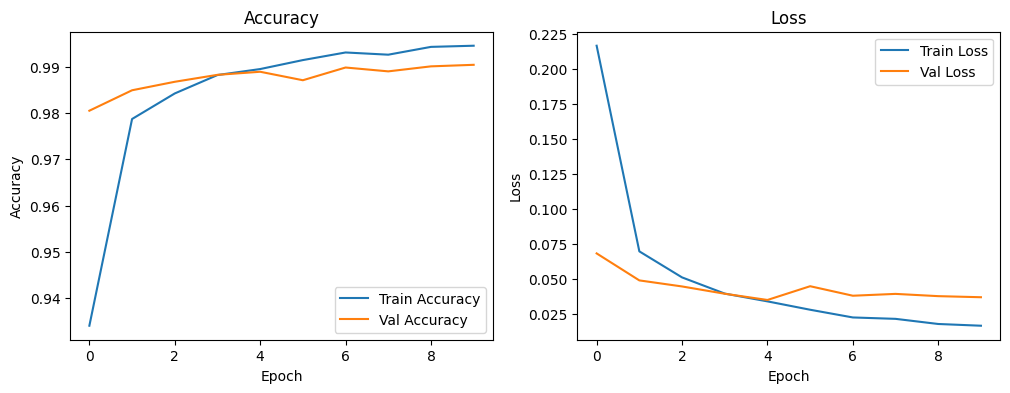

In [22]:
# 9a) Accuracy and Loss graphs on Traning and Validation
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Val Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Loss")
plt.show()

Using: test.csv


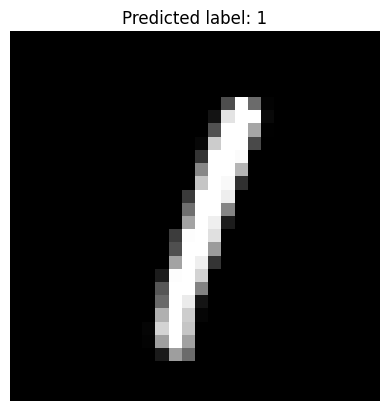

Predicted label: 1


In [23]:
# %% STEP 10: predict on one test image (Colab + local)
import os
import glob
import numpy as np
import pandas as pd

TEST_CANDIDATES = [
    'test.csv', 'lab08/test.csv', '/content/test.csv',
    '/kaggle/input/digit-recognizer/test.csv',
] + glob.glob('/kaggle/input/*/test.csv') + glob.glob('/content/*/test.csv')

TEST_PATH = next((p for p in TEST_CANDIDATES if os.path.exists(p)), None)
assert TEST_PATH is not None, 'Run the STEP 2 cell first - it creates test.csv as a fallback.'
print('Using:', TEST_PATH)

test_df = pd.read_csv(TEST_PATH)
X_test = (test_df.values.astype('float32') / 255.0).reshape(-1, 28, 28, 1)

idx = 5                                    # any image index

probs = model.predict(X_test[idx:idx+1], verbose=0)   # a single image
label = np.argmax(probs)

plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
plt.title(f'Predicted label: {label}')
plt.axis('off')
plt.show()

print('Predicted label:', label)


Using: images.png


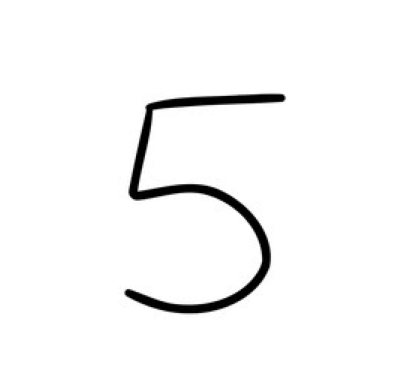

In [24]:
# %% STEP 11: show images.png (Colab + local)
import os
from PIL import Image

IMG_CANDIDATES = ['images.png', 'lab08/images.png', '/content/images.png']
img_path = next((p for p in IMG_CANDIDATES if os.path.exists(p)), None)
if img_path is None:
    import urllib.request
    url = 'https://raw.githubusercontent.com/manaal6/Introduction_To_AI_Lab_Tasks/main/lab08/images.png'
    print('Downloading:', url)
    img_path = 'images.png'
    urllib.request.urlretrieve(url, img_path)
print('Using:', img_path)

img = Image.open(img_path)
plt.imshow(img)
plt.axis('off')
plt.show()
